In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df_temp = pd.read_csv('../Part1_analysis/target_temp_WCE_quadr_moanom.csv')
df_temp_terc = pd.read_csv('../Part1_analysis/westerncentral_temperature_terc_cat_new.csv')

In [3]:
df_snow = pd.read_csv('../Part1_analysis/snow_WCE_week3.csv')

In [4]:
low_temp_train = df_snow[:5040][df_temp_terc[:5040]['tercile_category']==0]['snow_depth']
medium_temp_train = df_snow[:5040][df_temp_terc[:5040]['tercile_category']==1]['snow_depth']
high_temp_train = df_snow[:5040][df_temp_terc[:5040]['tercile_category']==2]['snow_depth']

low_temp_test = df_snow[5040:][df_temp_terc[5040:]['tercile_category']==0]['snow_depth']
medium_temp_test = df_snow[5040:][df_temp_terc[5040:]['tercile_category']==1]['snow_depth']
high_temp_test = df_snow[5040:][df_temp_terc[5040:]['tercile_category']==2]['snow_depth']

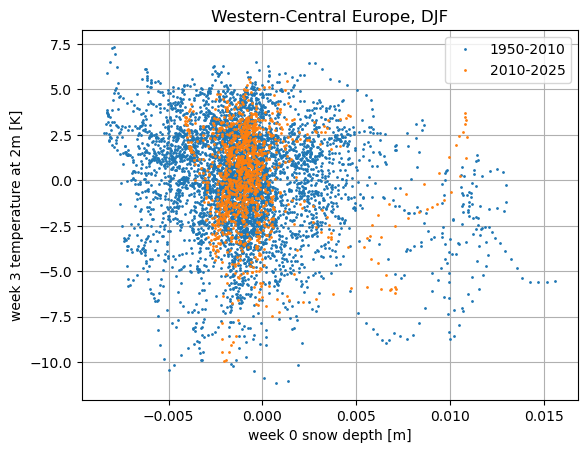

In [9]:
plt.plot(df_snow['snow_depth'][:5040], df_temp['t2m'][:5040], 'o', markersize=1, label='1950-2010')
plt.plot(df_snow['snow_depth'][5040:], df_temp['t2m'][5040:], 'o', markersize=1, label='2010-2025')
plt.xlabel('week 0 snow depth [m]')
plt.ylabel('week 3 temperature at 2m [K]')
plt.title('Western-Central Europe, DJF')
plt.legend()
plt.grid()

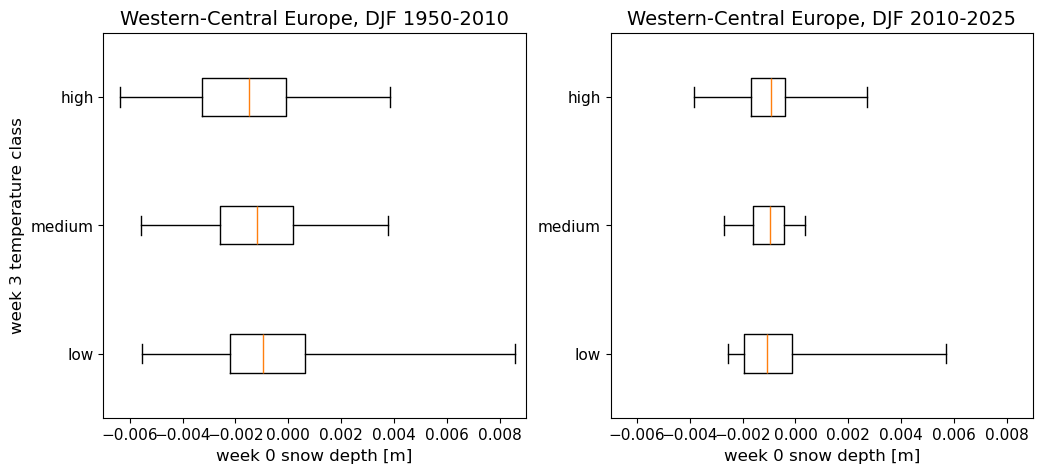

In [5]:
fig, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].boxplot([low_temp_train, medium_temp_train, high_temp_train], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[0].set_xlabel('week 0 snow depth [m]',fontsize=12)
ax[0].set_ylabel('week 3 temperature class',fontsize=12)
ax[0].set_title('Western-Central Europe, DJF 1950-2010',fontsize=14)
ax[0].set_xlim((-0.007,0.009))
ax[0].tick_params(labelsize=11)

ax[1].boxplot([low_temp_test, medium_temp_test, high_temp_test], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[1].set_xlabel('week 0 snow depth [m]',fontsize=12)
ax[1].set_title('Western-Central Europe, DJF 2010-2025',fontsize=14)
ax[1].set_xlim((-0.007,0.009))
ax[1].tick_params(labelsize=11)

plt.savefig('WCE_temp_snow_box.pdf', bbox_inches='tight')